In [1258]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("../data/dataGB.xlsx")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162097 entries, 0 to 162096
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype 
---  ------                       --------------   ----- 
 0   product_sku_code             162097 non-null  int64 
 1   customer                     162097 non-null  object
 2   year                         162097 non-null  int64 
 3   yearweek                     162097 non-null  int64 
 4   nielsen_total_volume         162097 non-null  int64 
 5   promotion_indicator          162097 non-null  int64 
 6   top_brand                    162097 non-null  object
 7   flavor_internal              162097 non-null  object
 8   pack_type_internal           162097 non-null  object
 9   pack_size_internal           162097 non-null  object
 10  units_per_package_internal   162097 non-null  object
 11  material_medium_description  162097 non-null  object
dtypes: int64(5), object(7)
memory usage: 14.8+ MB


In [1259]:

df.head()

,product_sku_code,customer,year,yearweek,nielsen_total_volume,promotion_indicator,top_brand,flavor_internal,pack_type_internal,pack_size_internal,units_per_package_internal,material_medium_description
0,264471,L2_ASDA,2022,202244,2769,1,MONSTER,MANGO,CAN,500ML,X4,500MLCAN 6X4P MNSTR MNG LOCO
1,279358,L2_ASDA,2022,202244,528,0,MONSTER,CHERRY,CAN,500ML,X4,500MLCAN 6X4P MNSTR ULTRA BLK
2,279418,L2_ASDA,2022,202244,1067,0,MONSTER,MANGO,CAN,500ML,X1,500MLCAN X12 MNSTR ULTRA FIESTA
3,284408,L2_ASDA,2022,202244,68,1,SCHWEPPES DIET,TONIC,GLASS,600ML,X1,600MLNRG X6 SW SIMLN TNIC
4,284804,L2_ASDA,2022,202244,16,0,COSTA,CARAMEL,PET,250ML,X1,250MLNRP X12 CSTA FR CRML SWRL


In [1260]:
print(df[df["customer"] == "L2_ASDA"]["nielsen_total_volume"].sum())
print(df[df["customer"] == "L2_TESCO"]["nielsen_total_volume"].sum())
print(df[df["customer"] == "L2_SAINSBURY'S"]["nielsen_total_volume"].sum())
print(df[df["customer"] == "L2_MORRISONS"]["nielsen_total_volume"].sum())

218837717
539640187
162465587
131655789


In [1261]:
df_tesco = df[(df["customer"] == "L2_TESCO") & (df["product_sku_code"] == 409168)]
df_tesco.head()
#df_tesco.info()

,product_sku_code,customer,year,yearweek,nielsen_total_volume,promotion_indicator,top_brand,flavor_internal,pack_type_internal,pack_size_internal,units_per_package_internal,material_medium_description
12646,409168,L2_TESCO,2022,202248,69439,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC
13233,409168,L2_TESCO,2023,202324,90828,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC
13477,409168,L2_TESCO,2023,202335,74921,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC
13497,409168,L2_TESCO,2023,202336,90659,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC
13550,409168,L2_TESCO,2023,202338,73688,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC


In [1262]:
df_tesco = df_tesco.sort_values(['product_sku_code', 'date'])
df_tesco.head()

KeyError: 'date'

/home/zawgyi/sch-coding/baseline-sales-modelling/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


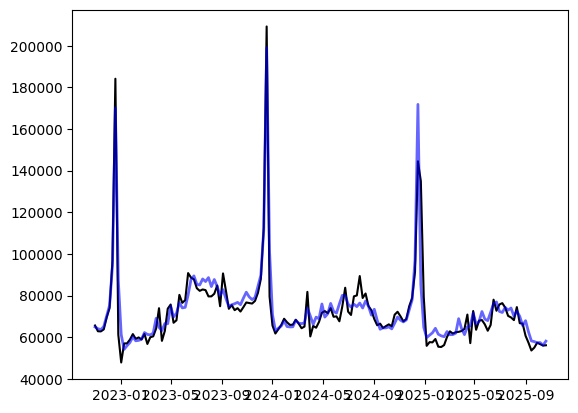

In [ ]:

from statsmodels.tsa.api import ExponentialSmoothing

test_df = df_tesco.copy()

es = ExponentialSmoothing(test_df["nielsen_total_volume"], 
                          trend="mul", 
                          seasonal="mul",
                          seasonal_periods= 52,
                          initialization_method="estimated").fit()
test_df["nielsen_total_volume"] = es.fittedvalues
plt.plot(df_tesco["date"], df_tesco["nielsen_total_volume"], label="Actual Sales", color="black")
plt.plot(df_tesco["date"], es.fittedvalues, label="SES Baseline (Fitted)", color="blue", linewidth=2, alpha = 0.6)

# Seasonality functions

In [1280]:

def preprocess_date(df):
    df = df.copy()
    df["date"] = pd.to_datetime(
        df["yearweek"].astype(str) + "-1",
        format="%G%V-%u"
    )
    df = df.sort_values("date")
    return df

def create_features_seasonality(df):
    df = df.copy()
    df = df.sort_values(['product_sku_code', 'date'])
    #df = df.groupby('product_sku_code')
    df["week"] = df["date"].dt.isocalendar().week.astype(int)
    df["month"] = df["date"].dt.month

    lags = [1, 4, 13] # 1 week, 1 month (4wks), 3 months

    for lag in lags:
        df[f"lag_{lag}"] = df["nielsen_total_volume"].shift(lag)
    
    # rolling avg
    windows = [4, 13, 26]
    for window in windows:
        df[f"rolling_mean_{window}"] = (
            df["nielsen_total_volume"]
            .shift(1)
            .rolling(window)
            .mean()
        )

    # rolling median
    windows = [4, 13, 26]
    for window in windows:
        df[f"rolling_median_{window}"] = (
            df["nielsen_total_volume"]
            .shift(1)
            .rolling(window)
            .median()
        )
    
    # is december
    df['is_christmas_peak'] = df['month'].isin([12]).astype(int)
    return df

def create_smooth_seasonality_and_return_model(df):
    df = df.copy()
    smoothing = ExponentialSmoothing(df["nielsen_total_volume"], 
                            trend="mul", 
                            seasonal="mul",
                            seasonal_periods= 52,
                            initialization_method="estimated").fit()
    df["smoothed_volume"] = smoothing.fittedvalues
    return df, smoothing

def my_split(df, test_size, features, target):
    split_idx = int(len(df) * test_size)
    train_df = df.iloc[:split_idx]
    test_df = df.iloc[split_idx:]

    X_train = train_df[features]
    X_test = test_df[features]
    y_train = train_df[target]
    y_test = test_df[target]

    return X_train, X_test, y_train, y_test



#features_df_tesco = create_features_seasonality(df_tesco)
#features_df_tesco.head()
#features_df_tesco.tail()

In [ ]:
from sklearn.model_selection import train_test_split

features_seasonality = ["product_sku_code",
    #"customer",
    "year",
    "month",
    "week",
    #"top_brand",
    #"flavor_internal",
    #"pack_type_internal",
    #"pack_size_internal",
    #"units_per_package_internal",
    "lag_1",
    "lag_4",
    "lag_13",
    "smoothed_volume"
    #"rolling_mean_4",
    #"rolling_mean_13",
    #"rolling_mean_26"
]

split_idx = int(len(features_df_tesco) * 0.7)
tmp_train = features_df_tesco.iloc[:split_idx]
tmp_test = features_df_tesco.iloc[split_idx:]

tmp_train, es_model = create_smooth_seasonality_and_return_model(tmp_train)

tmp_test["smoothed_volume"] = es_model.forecast(len(tmp_test))

X_train = tmp_train[features_seasonality]
X_test = tmp_test[features_seasonality]
y_train = tmp_train["nielsen_total_volume"]
y_test = tmp_test["nielsen_total_volume"]


/home/zawgyi/sch-coding/baseline-sales-modelling/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/home/zawgyi/sch-coding/baseline-sales-modelling/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/home/zawgyi/sch-coding/baseline-sales-modelling/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/tmp/ipykernel_916/3276852084.py:28: SettingWithCopyWarning: 
A value is trying to be se

In [ ]:
X_train.tail()

,product_sku_code,year,month,week,lag_1,lag_4,lag_13,smoothed_volume
103349,409168,2024,10,44,70860.0,65374.0,89398.0,71027.410439
142353,409168,2024,11,45,72258.0,66210.0,78872.0,69819.485098
44741,409168,2024,11,46,70094.0,65260.0,81020.0,69002.009039
44750,409168,2024,11,47,67667.0,70860.0,75014.0,69643.207389
161423,409168,2024,11,48,68787.0,72258.0,72991.0,74376.064753


In [ ]:
import lightgbm as lgb
# faster xgboost from microsoft

model_seasonality = lgb.LGBMRegressor(
    n_estimators=1000,          
    learning_rate=0.01,         
    num_leaves=20,              
    max_depth=5,                
    min_child_samples=10,       
    reg_alpha=0.1,              
    reg_lambda=0.1,             
    importance_type='gain',     
    random_state=42
)

model_seasonality.fit(X_train, y_train)

preds = model_seasonality.predict(X_test)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000045 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 193
[LightGBM] [Info] Number of data points in the train set: 109, number of used features: 7
[LightGBM] [Info] Start training from score 74168.073394
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

In [ ]:
features_df_tesco.tail()

,product_sku_code,customer,year,nielsen_total_volume,promotion_indicator,top_brand,flavor_internal,pack_type_internal,pack_size_internal,units_per_package_internal,material_medium_description,date,week,month,lag_1,lag_4,lag_13,rolling_mean_4,rolling_mean_13,rolling_mean_26
94176,409168,L2_TESCO,2025,55031,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC,2025-09-22,39,9,53662.0,66554.0,72746.0,59589.75,68221.692308,67326.730769
74740,409168,L2_TESCO,2025,57405,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC,2025-09-29,40,9,55031.0,60724.0,75752.0,56709.00,66859.000000,67035.038462
104048,409168,L2_TESCO,2025,56688,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC,2025-10-06,41,10,57405.0,57419.0,76394.0,55879.25,65447.692308,66819.000000
152559,409168,L2_TESCO,2025,56030,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC,2025-10-13,42,10,56688.0,53662.0,74282.0,55696.50,63931.846154,66535.884615
74783,409168,L2_TESCO,2025,56172,0,COCA-COLA,COLA,CAN,330ML,X24,330MLCAN 24P COKE CLASSIC,2025-10-20,43,10,56030.0,55031.0,70269.0,56288.50,62527.846154,65963.846154


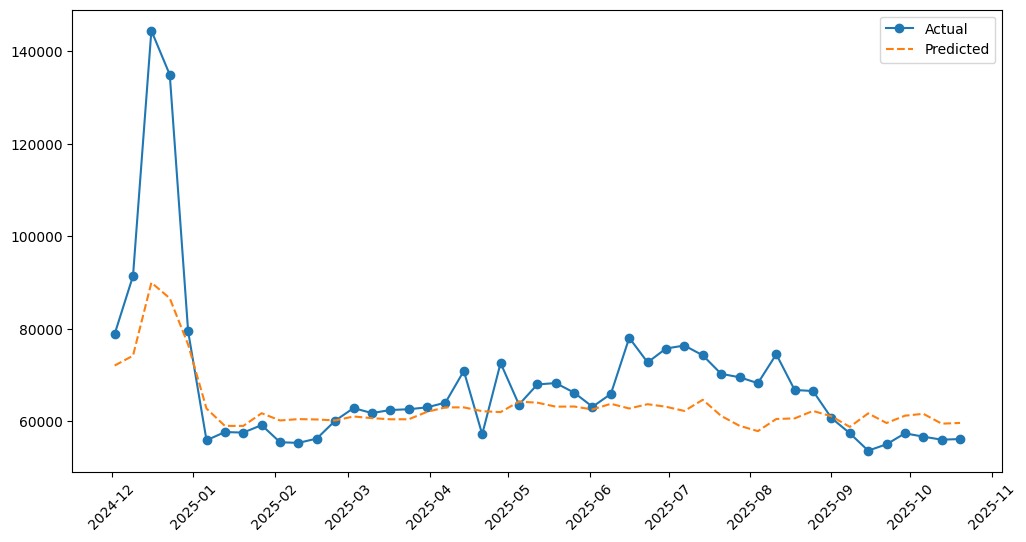

In [ ]:
import matplotlib.pyplot as plt


def plot_pred(processed_df, X_test, y_test, preds):
    test_dates = processed_df.loc[X_test.index, 'date']

    plot_df = pd.DataFrame({
        'date': test_dates,
        'actual': y_test,
        'predicted': preds
    }).sort_values('date')

    plt.figure(figsize=(12, 6))
    plt.plot(plot_df['date'], plot_df['actual'], label='Actual', marker='o')
    plt.plot(plot_df['date'], plot_df['predicted'], label='Predicted', linestyle='--')
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

plot_pred(features_df_tesco, X_test, y_test, preds)

In [ ]:
importances = model_seasonality.feature_importances_
fi_df = pd.DataFrame({
    "feature": features_seasonality,
    "importance": importances
}).sort_values("importance", ascending=False)

fi_df

,feature,importance
7,smoothed_volume,9.208799e+11
4,lag_1,3.406368e+11
3,week,2.230214e+11
5,lag_4,6.631007e+10
6,lag_13,3.004873e+10
2,month,2.527076e+10
1,year,6.166176e+07
0,product_sku_code,0.000000e+00


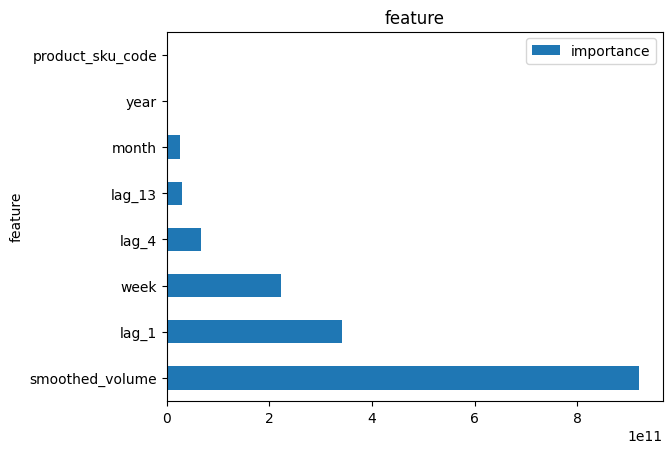

In [ ]:
fi_df.plot.barh(x='feature', y='importance')
plt.title("feature importances")
plt.title("feature")
plt.show()

# Test with different product

In [ ]:
new_df = df[(df["customer"] == "L2_TESCO") & (df["product_sku_code"] == 419293)]
# this data has promotion so its inaccurate
new_df = preprocess_date(new_df)
new_df = create_features_seasonality(new_df)
new_df.tail()

,product_sku_code,customer,year,yearweek,nielsen_total_volume,promotion_indicator,top_brand,flavor_internal,pack_type_internal,pack_size_internal,...,material_medium_description,date,week,month,lag_1,lag_4,lag_13,rolling_mean_4,rolling_mean_13,rolling_mean_26
162029,419293,L2_TESCO,2025,202539,292521,1,COCA-COLA ZERO / NO SUGAR,COLA,CAN,330ML,...,330MLCAN 24P COCA-COLA ZRO,2025-09-22,39,9,195025.0,212088.0,57317.0,124077.75,207200.076923,194620.615385
45381,419293,L2_TESCO,2025,202540,127141,1,COCA-COLA ZERO / NO SUGAR,COLA,CAN,330ML,...,330MLCAN 24P COCA-COLA ZRO,2025-09-29,40,9,292521.0,45115.0,69117.0,144186.00,225292.692308,204414.153846
55184,419293,L2_TESCO,2025,202541,33075,0,COCA-COLA ZERO / NO SUGAR,COLA,CAN,330ML,...,330MLCAN 24P COCA-COLA ZRO,2025-10-06,41,10,127141.0,44083.0,326226.0,164692.50,229756.076923,208075.807692
16053,419293,L2_TESCO,2025,202542,41807,0,COCA-COLA ZERO / NO SUGAR,COLA,CAN,330ML,...,330MLCAN 24P COCA-COLA ZRO,2025-10-13,42,10,33075.0,195025.0,562091.0,161940.50,207206.000000,207731.538462
113803,419293,L2_TESCO,2025,202543,44787,0,COCA-COLA ZERO / NO SUGAR,COLA,CAN,330ML,...,330MLCAN 24P COCA-COLA ZRO,2025-10-20,43,10,41807.0,292521.0,223565.0,123636.00,167184.153846,207342.653846


In [ ]:
split_idx = int(len(new_df) * 0.7) 
tmp_train = new_df.iloc[:split_idx]
tmp_test = new_df.iloc[split_idx:]

tmp_train, es_model = create_smooth_seasonality_and_return_model(tmp_train)
tmp_test["smoothed_volume"] = es_model.forecast(len(tmp_test))

X_train, X_test = tmp_train[features_seasonality], tmp_test[features_seasonality],
y_train, y_test = tmp_train["nielsen_total_volume"], tmp_test["nielsen_total_volume"]
model_seasonality.fit(X_train, y_train)

/home/zawgyi/sch-coding/baseline-sales-modelling/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/home/zawgyi/sch-coding/baseline-sales-modelling/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/home/zawgyi/sch-coding/baseline-sales-modelling/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/tmp/ipykernel_916/308831894.py:6: SettingWithCopyWarning: 
A value is trying to be set 

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000019 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 193
[LightGBM] [Info] Number of data points in the train set: 109, number of used features: 7
[LightGBM] [Info] Start training from score 176422.009174
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

,boosting_type,'gbdt'
,num_leaves,20
,max_depth,5
,learning_rate,0.01
,n_estimators,1000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,10


In [ ]:
new_pred = model_seasonality.predict(X_test)

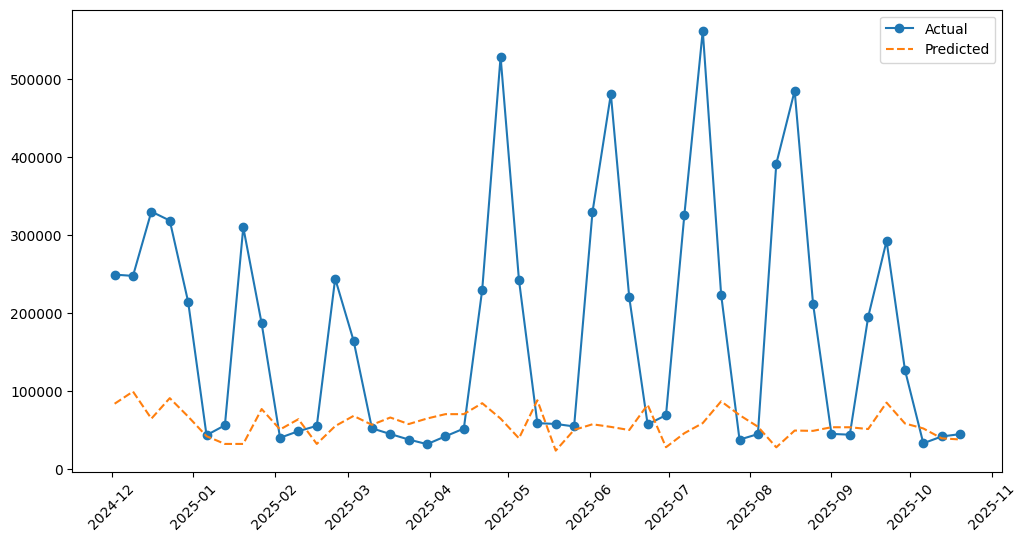

In [ ]:
plot_pred(new_df, X_test, y_test, new_pred)

# Promotion uplift model

For this we will use product code **409168** to train the seasonality model as it has 0 promotion thoroughout the entire data set. Then we will use the seasonality model to predict the entire training data set of the code **419293** which will serve as a baseline.

The prediction from seasonality model will be subtracted from the second dataset.
Then promodion model will then be trained on this subtracted dataframe
The prediction will be the sum of the two models.

In [1635]:
features_seasonality = ["product_sku_code",
    #"customer",
    "year",
    "month",
    "week",
    #"top_brand",
    #"flavor_internal",
    #"pack_type_internal",
    #"pack_size_internal",
    #"units_per_package_internal",
    "lag_1",
    "lag_4",
    "lag_13",
    #"smoothed_volume"
    "rolling_mean_4",
    "rolling_mean_13",
    #"rolling_mean_26",
    "is_christmas_peak"
]


features_promotion = [
    #"customer",
    "year",
    "month",
    "week",
    #"top_brand",
    #"flavor_internal",
    #"pack_type_internal",
    #"pack_size_internal",
    #"units_per_package_internal",
    "promotion_indicator",
    "promo_lag_1",
    "promo_lag_2",
    "promo_lag_3",
    "promo_lag_4",
    #"promo_rolling_mean_4",
    "promo_rolling_median_4",
    "promo_rolling_median_8",
    "wk_since_last_promo",
    #"parabolic_lag_4",
    #"parabolic_lag_8",
    #"parabolic_lag_4_v2",
    #"parabolic_lag_8_v2"
]

#seasonality_sku = 409168 # 0 promotion
seasonality_sku = 407009 # 0 prmotion SB

#promotion_sku = 217852 # 149 promotion
#promotion_sku = 216907 # 149 promotion
#promotion_sku = 419293 # 93 promotion
#promotion_sku = 409175 # 86 promotion
#promotion_sku = 641420 # 51 promotion
#promotion_sku = 643424 # 15 promotion low sales
#promotion_sku = 283978 # 9 promotion
#promotion_sku = 408982 # 5 promotion
#promotion_sku = 408748 # SB 82 promotion wierd data
promotion_sku = 216907 # SB 107 promotion
#promotion_sku = 217852 # SB 112 promotion
#promotion_sku = 201050 # SB
#promotion_sku = 207883 # SB

#customer = "L2_TESCO"
customer = "L2_SAINSBURY'S"

df_no_promo = df[(df["customer"] == customer) & (df["product_sku_code"] == seasonality_sku)].copy()
#df.head()

df_no_promo = preprocess_date(df_no_promo)
df_no_promo = create_features_seasonality(df_no_promo)

split_idx = int(len(df_no_promo) * 0.7)
tmp_train = df_no_promo.iloc[:split_idx]
tmp_test = df_no_promo.iloc[split_idx:]

#tmp_train, es_model = create_smooth_seasonality_and_return_model(tmp_train)

#tmp_test["smoothed_volume"] = es_model.forecast(len(tmp_test))

X_train = tmp_train[features_seasonality]
X_test = tmp_test[features_seasonality]
y_train = tmp_train["nielsen_total_volume"]
y_test = tmp_test["nielsen_total_volume"]

model_seasonality = lgb.LGBMRegressor(
    n_estimators=1000,          
    learning_rate=0.01,         
    num_leaves=20,              
    max_depth=5,                
    min_child_samples=10,       
    reg_alpha=0.1,              
    reg_lambda=0.1,             
    importance_type='gain',     
    random_state=42
)

model_seasonality.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000020 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 224
[LightGBM] [Info] Number of data points in the train set: 109, number of used features: 8
[LightGBM] [Info] Start training from score 6306.330275
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

,boosting_type,'gbdt'
,num_leaves,20
,max_depth,5
,learning_rate,0.01
,n_estimators,1000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,10


In [1636]:

X_train.tail()

,product_sku_code,year,month,week,lag_1,lag_4,lag_13,rolling_mean_4,rolling_mean_13,is_christmas_peak
72014,407009,2024,10,44,6166.0,5967.0,5789.0,5993.50,5632.000000,0
159436,407009,2024,11,45,6148.0,5952.0,5323.0,6038.75,5659.615385,0
11532,407009,2024,11,46,5495.0,5889.0,5549.0,5924.50,5672.846154,0
101379,407009,2024,11,47,6086.0,6166.0,5371.0,5973.75,5714.153846,0
32931,407009,2024,11,48,6371.0,6148.0,5464.0,6025.00,5791.076923,0


In [1637]:
df_target = df[(df["customer"] == customer) & (df["product_sku_code"] == promotion_sku)].copy()
df_target = preprocess_date(df_target)
df_target = create_features_seasonality(df_target)

split_idx = int(len(df_target) * 0.7)

og_train = df_target.iloc[:split_idx].copy()
og_test = df_target.iloc[split_idx:].copy()
#og_train, es_model = create_smooth_seasonality_and_return_model(og_train)
#og_test["smoothed_volume"] = es_model.forecast(len(og_test))

og_train.tail()

,product_sku_code,customer,year,yearweek,nielsen_total_volume,promotion_indicator,top_brand,flavor_internal,pack_type_internal,pack_size_internal,...,lag_1,lag_4,lag_13,rolling_mean_4,rolling_mean_13,rolling_mean_26,rolling_median_4,rolling_median_13,rolling_median_26,is_christmas_peak
32835,216907,L2_SAINSBURY'S,2024,202440,23383,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,40231.0,11421.0,29167.0,30139.25,26544.307692,25805.115385,34297.5,28364.0,26406.0,0
62226,216907,L2_SAINSBURY'S,2024,202441,14956,0,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,23383.0,28364.0,19807.0,33129.75,26099.384615,25361.846154,34297.5,23383.0,23915.5,0
52395,216907,L2_SAINSBURY'S,2024,202442,14308,0,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,14956.0,40541.0,15405.0,29777.75,25726.230769,24505.692308,31807.0,23383.0,22702.5,0
140286,216907,L2_SAINSBURY'S,2024,202443,14184,0,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,14308.0,40231.0,13432.0,23219.50,25641.846154,24279.615385,19169.5,23383.0,22702.5,0
62270,216907,L2_SAINSBURY'S,2024,202444,26262,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,14184.0,23383.0,31972.0,16707.75,25699.692308,24385.192308,14632.0,23383.0,22702.5,0


In [1638]:
X_og_train, X_og_test = og_train[features_seasonality], og_test[features_seasonality]
y_og_train, y_og_test = og_train["nielsen_total_volume"], og_test["nielsen_total_volume"]
baseline_train = model_seasonality.predict(X_og_train)
baseline_test = model_seasonality.predict(X_og_test)

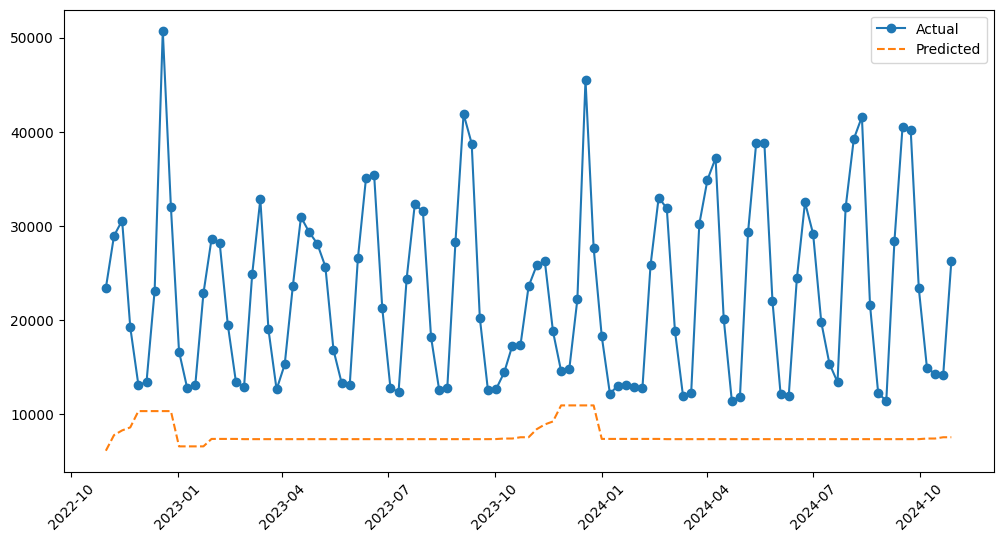

,product_sku_code,customer,year,yearweek,nielsen_total_volume,promotion_indicator,top_brand,flavor_internal,pack_type_internal,pack_size_internal,...,lag_1,lag_4,lag_13,rolling_mean_4,rolling_mean_13,rolling_mean_26,rolling_median_4,rolling_median_13,rolling_median_26,is_christmas_peak
72625,216907,L2_SAINSBURY'S,2025,202539,24731,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,24926.0,28302.0,23404.0,25777.75,25491.923077,24160.192308,25178.0,24926.0,24896.0,0
101896,216907,L2_SAINSBURY'S,2025,202540,25544,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,24731.0,25430.0,23523.0,24885.00,25594.000000,24269.615385,24828.5,24926.0,24896.0,0
150444,216907,L2_SAINSBURY'S,2025,202541,25605,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,25544.0,24453.0,24041.0,24913.50,25749.461538,24342.000000,24828.5,25430.0,24983.0,0
92135,216907,L2_SAINSBURY'S,2025,202542,26720,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,25605.0,24926.0,23071.0,25201.50,25869.769231,24288.346154,25235.0,25544.0,24983.0,0
33551,216907,L2_SAINSBURY'S,2025,202543,28098,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,26720.0,24731.0,24866.0,25650.00,26150.461538,24271.076923,25574.5,25605.0,24983.0,0


In [1639]:
plot_pred(df_target, X_og_train, y_og_train, baseline_train)
#X_og_train.head()
df_target.tail()


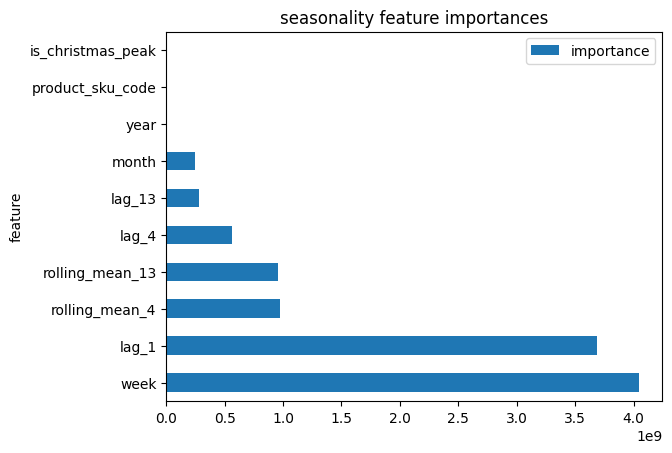

In [1640]:
importances = model_seasonality.feature_importances_
fi_df = pd.DataFrame({
    "feature": features_seasonality,
    "importance": importances
}).sort_values("importance", ascending=False)

fi_df.plot.barh(x='feature', y='importance')
plt.title("seasonality feature importances")
plt.show()

In [1641]:
def create_features_promotion(df):
    df = df.copy()
    df = df.sort_values(['product_sku_code', 'date'])
    #df = df.groupby('product_sku_code')
    df["week"] = df["date"].dt.isocalendar().week.astype(int)
    df["month"] = df["date"].dt.month

    lags = [1, 2, 3, 4] # 1 -> 4 weeks

    for lag in lags:
        df[f"promo_lag_{lag}"] = df["nielsen_total_volume"].shift(lag)
    
    # rolling avg
    windows = [4]
    for window in windows:
        df[f"promo_rolling_mean_{window}"] = (
            df["nielsen_total_volume"]
            .shift(1)
            .rolling(window)
            .mean()
        )
    
    # rolling median
    windows = [4, 8]
    for window in windows:
        df[f"promo_rolling_median_{window}"] = (
            df["nielsen_total_volume"]
            .shift(1)
            .rolling(window)
            .median()
        )
    
    # wks since last promo
    df['group'] = (df['promotion_indicator'] != df['promotion_indicator'].shift()).cumsum()


    # 2. Use cumcount to start the counter at 0 for each group. 
    # We add +1 because your example shows the first promo week starting at 1.
    df['wk_since_last_promo'] = df.groupby('group').cumcount() + 1

    # 3. Use .loc to force the counter back to 0 whenever the promo is not active (0)
    df.loc[df['promotion_indicator'] == 0, 'wk_since_last_promo'] = 0

    # 4. Clean up the temporary group column
    df = df.drop(columns=['group'])

    # parabolic prediction 
    promo_window = [4, 8]
    for T in promo_window:
        df[f"parabolic_lag_{T}"] = (
            df["promo_lag_1"] + 
            ((-8/(T**2)) * df["promo_lag_1"] * (df["promo_lag_1"] - T))
        )

    # real parabolic 
    promo_window = [4, 8]
    for T in promo_window:
        df[f"parabolic_lag_{T}_v2"] = (
            df["promo_lag_1"] + 
            ((-8/(T**2)) * df["wk_since_last_promo"] * (df["wk_since_last_promo"] - T)) * df["promo_lag_1"]
        )

    """
    """

    return df

In [1642]:
df_residual = df_target.copy()
df_residual.loc[df_residual.index[:split_idx], "nielsen_total_volume"] = (
    df_target.iloc[:split_idx]["nielsen_total_volume"].values / baseline_train.astype(float)
)

df_residual.loc[df_residual.index[split_idx:], "nielsen_total_volume"] = (
    df_target.iloc[split_idx:]["nielsen_total_volume"].values / baseline_test.astype(float)
)


df_residual = create_features_promotion(df_residual)
df_residual.tail()

/tmp/ipykernel_916/886926713.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[3.81015134 3.71140878 3.68214724 2.23368891 1.26797417 1.29810195
 2.23534643 4.89962754 3.09311923 2.52225235 1.93793686 1.9870962
 3.45522101 3.86907426 3.81085105 2.63720079 1.8164021  1.75598619
 3.37360224 4.4521033  2.57780454 1.71465133 2.07514553 3.20338393
 4.19636926 3.97953064 3.8136491  3.4828347  2.2827685  1.80924718
 1.78431074 3.6001986  4.75676155 4.80040032 2.88395355 1.74121406
 1.67453619 3.31004143 4.37729397 4.27659954 2.4692497  1.7077396
 1.74094301 3.83018305 5.6791388  5.25332197 2.74504132 1.70272521
 1.71726669 1.94319298 2.32538337 2.2905495  3.11241919 3.06253094
 2.93664469 2.03232161 1.33197006 1.34784422 2.02724018 4.15300966
 2.52809742 2.47036629 1.65091849 1.76506841 1.77155267 1.74210334
 1.7271085  3.49055584 4.46170821 4.32091594 2.56127059 1.61653186
 1.66925075 4.09540378 4.73087644 

,product_sku_code,customer,year,yearweek,nielsen_total_volume,promotion_indicator,top_brand,flavor_internal,pack_type_internal,pack_size_internal,...,promo_lag_3,promo_lag_4,promo_rolling_mean_4,promo_rolling_median_4,promo_rolling_median_8,wk_since_last_promo,parabolic_lag_4,parabolic_lag_8,parabolic_lag_4_v2,parabolic_lag_8_v2
72625,216907,L2_SAINSBURY'S,2025,202539,3.351647,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,3.446379,3.835604,3.493507,3.412227,3.514073,20,4.428530,5.329726,-537.113852,-97.964162
101896,216907,L2_SAINSBURY'S,2025,202540,3.461828,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,3.313972,3.446379,3.372518,3.364861,3.471654,21,4.438172,5.299102,-594.917402,-111.023318
150444,216907,L2_SAINSBURY'S,2025,202541,3.439714,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,3.378075,3.313972,3.376380,3.364861,3.454104,22,4.393357,5.425625,-681.980206,-129.818567
92135,216907,L2_SAINSBURY'S,2025,202542,3.589500,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,3.351647,3.378075,3.407816,3.408894,3.443046,23,4.403326,5.400473,-748.137691,-144.897932
33551,216907,L2_SAINSBURY'S,2025,202543,3.706725,1,COCA-COLA ZERO / NO SUGAR,COLA,PET,2000ML,...,3.461828,3.351647,3.460672,3.450771,3.443046,24,4.326245,5.568436,-857.890480,-168.706496


In [1643]:

X_promo_train = df_residual.iloc[:split_idx][features_promotion]
X_promo_test = df_residual.iloc[split_idx:][features_promotion]

y_promo_train = df_residual.iloc[:split_idx]["nielsen_total_volume"]
y_promo_test = df_residual.iloc[split_idx:]["nielsen_total_volume"]

model_promotion = lgb.LGBMRegressor(
    n_estimators=2000,          
    learning_rate=0.05,         
    num_leaves=64,              
    max_depth=8,                
    min_child_samples=5,        
    reg_alpha=0.2,              
    reg_lambda=0.2,             
    colsample_bytree=0.8,       
    random_state=42
)

y_promo_train.info()
print("--------------")
X_promo_train.info()
model_promotion.fit(X_promo_train[features_promotion], y_promo_train)

<class 'pandas.core.series.Series'>
Index: 105 entries, 9614 to 62270
Series name: nielsen_total_volume
Non-Null Count  Dtype  
--------------  -----  
105 non-null    float64
dtypes: float64(1)
memory usage: 1.6 KB
--------------
<class 'pandas.core.frame.DataFrame'>
Index: 105 entries, 9614 to 62270
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   year                    105 non-null    int64  
 1   month                   105 non-null    int32  
 2   week                    105 non-null    int64  
 3   promotion_indicator     105 non-null    int64  
 4   promo_lag_1             104 non-null    float64
 5   promo_lag_2             103 non-null    float64
 6   promo_lag_3             102 non-null    float64
 7   promo_lag_4             101 non-null    float64
 8   promo_rolling_median_4  101 non-null    float64
 9   promo_rolling_median_8  97 non-null     float64
 10  wk_since_last_promo    

,boosting_type,'gbdt'
,num_leaves,64
,max_depth,8
,learning_rate,0.05
,n_estimators,2000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,5


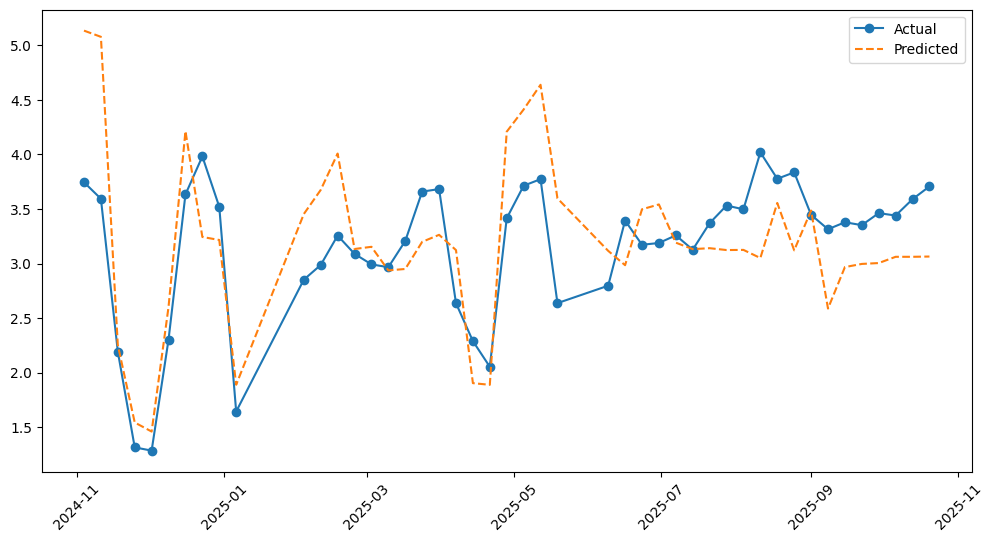

In [1644]:
promotion_pred = model_promotion.predict(X_promo_test)
plot_pred(df_residual, X_promo_test, y_promo_test, promotion_pred)

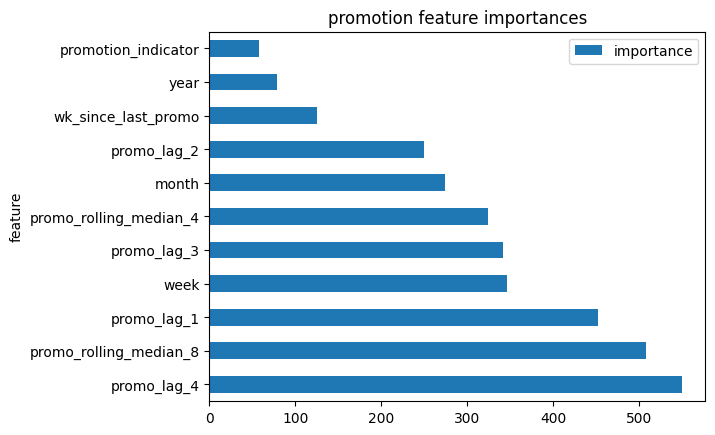

In [1645]:
importances = model_promotion.feature_importances_
fi_df = pd.DataFrame({
    "feature": features_promotion,
    "importance": importances
}).sort_values("importance", ascending=False)

fi_df.plot.barh(x='feature', y='importance')
plt.title("promotion feature importances")
plt.show()

# Combined Model

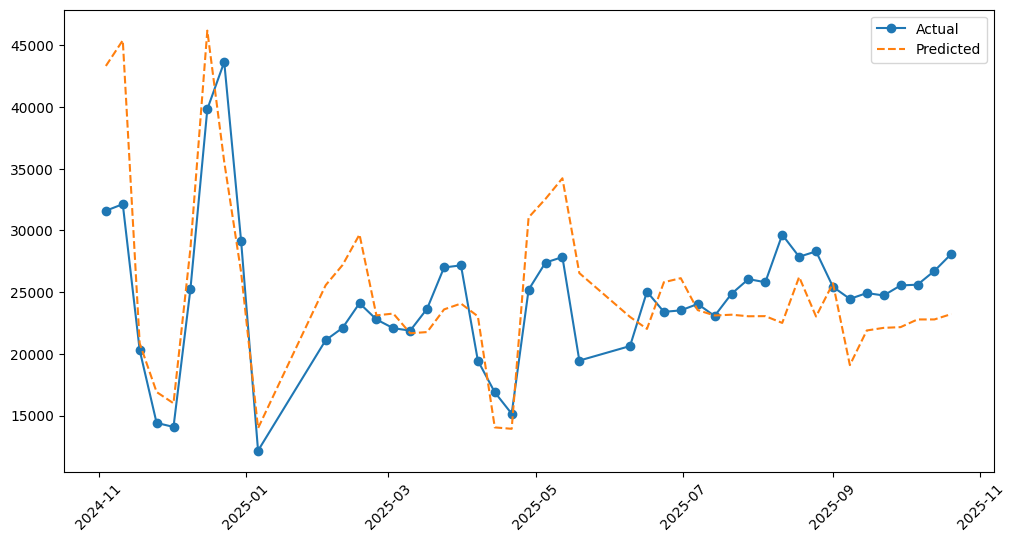

In [1646]:
combined_pred = baseline_test * promotion_pred

plot_pred(df_target, X_og_test, y_og_test, combined_pred)

In [1647]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


mae = mean_absolute_error(y_og_test, combined_pred)
rmse = np.sqrt(mean_squared_error(y_og_test, combined_pred))
r2 = r2_score(y_og_test, combined_pred)
# Function to calculate MAPE
def calculate_mape(y_true, y_pred): 
    # We add 1e-10 to avoid division by zero errors if sales were ever 0
    return np.mean(np.abs((y_true - y_pred) / (y_true + 1e-10))) * 100

mape_total = calculate_mape(y_og_test, combined_pred)
print(f"Total Model Accuracy: {100 - mape_total:.2f}%")

# Weighted MAPE
wmape = (np.sum(np.abs(y_og_test - combined_pred)) / np.sum(y_og_test)) * 100
print(f"Total Model Accuracy (WMAPE): {100 - wmape:.2f}%")

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2:   {r2:.2f}")

Total Model Accuracy: 85.61%
Total Model Accuracy (WMAPE): 85.17%
MAE:  3655.26
RMSE: 4567.32
R2:   0.35


In [1648]:
import numpy as np

def run_diagnostic(y_true, y_pred):
    # WMAPE: The 'Real' accuracy for retail
    wmape = (np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)) * 100
    
    # MBE: Tells us if the model is 'shifted' up or down
    mbe = np.mean(y_pred - y_true)
    
    # Variance Ratio: Are we predicting the 'spikes'?
    # (If < 1.0, the model is too flat/conservative)
    var_ratio = np.var(y_pred) / np.var(y_true)
    
    print(f"Accuracy (WMAPE): {100 - wmape:.2f}%")
    print(f"Bias (MBE): {mbe:.2f} units")
    print(f"Variance Ratio: {var_ratio:.2f}")

# Example for one SKU
run_diagnostic(og_test['nielsen_total_volume'], combined_pred)

Accuracy (WMAPE): 85.17%
Bias (MBE): 424.52 units
Variance Ratio: 1.50


## testing without promo_lag_* to boost R2 value

In [1649]:


def preprocess_date(df):
    df = df.copy()
    df["date"] = pd.to_datetime(
        df["yearweek"].astype(str) + "-1",
        format="%G%V-%u"
    )
    df = df.sort_values("date")
    return df

def create_features_seasonality(df):
    df = df.copy()
    df = df.sort_values(['product_sku_code', 'date'])
    #df = df.groupby('product_sku_code')
    df["week"] = df["date"].dt.isocalendar().week.astype(int)
    df["month"] = df["date"].dt.month

    lags = [1, 4, 13] # 1 week, 1 month (4wks), 3 months

    for lag in lags:
        df[f"lag_{lag}"] = df["nielsen_total_volume"].shift(lag)
    
    # rolling avg
    windows = [4, 13, 26]
    for window in windows:
        df[f"rolling_mean_{window}"] = (
            df["nielsen_total_volume"]
            .shift(1)
            .rolling(window)
            .mean()
        )

    # rolling median
    windows = [4, 13, 26]
    for window in windows:
        df[f"rolling_median_{window}"] = (
            df["nielsen_total_volume"]
            .shift(1)
            .rolling(window)
            .median()
        )
    
    # is december
    df['is_christmas_peak'] = df['month'].isin([12]).astype(int)
    return df

def create_smooth_seasonality_and_return_model(df):
    df = df.copy()
    smoothing = ExponentialSmoothing(df["nielsen_total_volume"], 
                            trend="mul", 
                            seasonal="mul",
                            seasonal_periods= 52,
                            initialization_method="estimated").fit()
    df["smoothed_volume"] = smoothing.fittedvalues
    return df, smoothing

In [1650]:
def create_features_promotion(df):
    df = df.copy()
    df = df.sort_values(['product_sku_code', 'date'])
    #df = df.groupby('product_sku_code')
    df["week"] = df["date"].dt.isocalendar().week.astype(int)
    df["month"] = df["date"].dt.month

    lags = [1, 2, 3, 4] # 1 -> 4 weeks

    for lag in lags:
        df[f"promo_lag_{lag}"] = df["nielsen_total_volume"].shift(lag)
    
    # rolling avg
    windows = [4]
    for window in windows:
        df[f"promo_rolling_mean_{window}"] = (
            df["nielsen_total_volume"]
            .shift(1)
            .rolling(window)
            .mean()
        )
    
    # rolling median
    windows = [4, 8]
    for window in windows:
        df[f"promo_rolling_median_{window}"] = (
            df["nielsen_total_volume"]
            .shift(1)
            .rolling(window)
            .median()
        )
    
    # wks since last promo
    df['group'] = (df['promotion_indicator'] != df['promotion_indicator'].shift()).cumsum()

    # 2. Use cumcount to start the counter at 0 for each group. 
    # We add +1 because your example shows the first promo week starting at 1.
    df['wk_since_last_promo'] = df.groupby('group').cumcount() + 1

    # 3. Use .loc to force the counter back to 0 whenever the promo is not active (0)
    df.loc[df['promotion_indicator'] == 0, 'wk_since_last_promo'] = 0

    # 4. Clean up the temporary group column
    df = df.drop(columns=['group'])

    return df